# 01 · The French day-ahead market, 2019–2026

Exploration of the raw data downloaded by `fr-power fetch` (ENTSO-E Transparency Platform + Open-Meteo). Everything is averaged to hourly resolution, exactly as in the feature pipeline.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fr_power import data
from fr_power.features import daily_to_hourly, to_hourly

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

raw = data.load_raw("../data/raw")
price = to_hourly(raw[data.DA_PRICES])["day_ahead_price_eur_mwh"].dropna()
generation = to_hourly(raw[data.GENERATION]).reindex(price.index)
load = to_hourly(raw[data.LOAD_FORECAST]).reindex(price.index)["Forecasted Load"]
wind_solar = to_hourly(raw[data.WIND_SOLAR_FORECAST]).reindex(price.index).sum(axis=1)
weather = daily_to_hourly(raw[data.WEATHER], price.index)
print(f"{len(price):,} hourly prices, {price.index.min():%Y-%m-%d} -> {price.index.max():%Y-%m-%d}")

69,018 hourly prices, 2019-01-01 -> 2026-11-16


## Price level and volatility

The 2021–2022 energy crisis (gas price shock + record-low French nuclear availability from stress-corrosion outages) dominates the series: prices were multiplied by ~7 between 2019 and 2022. They fell back in 2024-2025 but remain far more volatile than before the crisis, with both deeper negative prices and higher peaks.

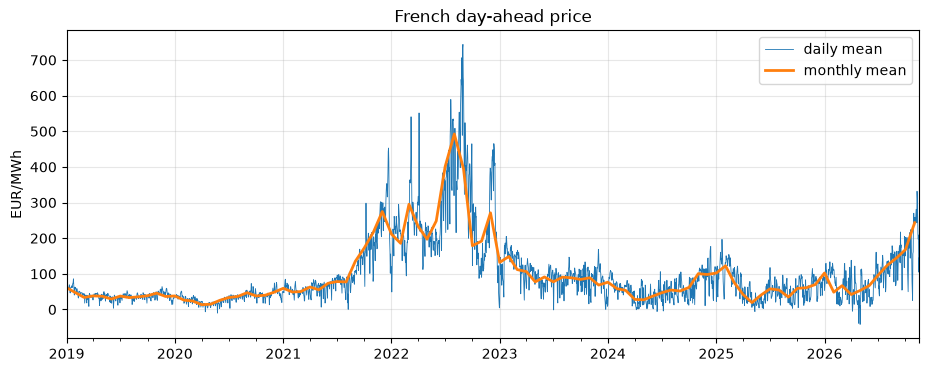

,mean,std,min,max,negative_hours
2019,39.4,14.0,-24.9,121.5,27
2020,32.2,16.1,-75.8,200.0,102
2021,109.2,84.3,-66.2,620.0,64
2022,275.9,145.8,-1.4,2987.8,4
2023,96.9,45.5,-134.9,276.1,147
2024,58.0,40.7,-87.3,284.2,352
2025,61.5,46.8,-118.0,473.3,509
2026,99.1,80.2,-497.8,550.0,521


In [2]:
fig, ax = plt.subplots()
price.resample("D").mean().plot(ax=ax, linewidth=0.6, label="daily mean")
price.resample("MS").mean().plot(ax=ax, linewidth=2, label="monthly mean")
ax.set(ylabel="EUR/MWh", xlabel="", title="French day-ahead price")
ax.legend()
plt.show()

yearly = price.groupby(price.index.year).agg(
    mean="mean", std="std", min="min", max="max",
    negative_hours=lambda s: int((s < 0).sum()),
)
yearly.round(1)

## Intraday shape: the solar dip

Average price by hour of day, per year. The midday trough deepens as solar capacity grows, and negative-price hours become frequent from 2024 onwards (2022 is left out: its level would flatten every other curve).

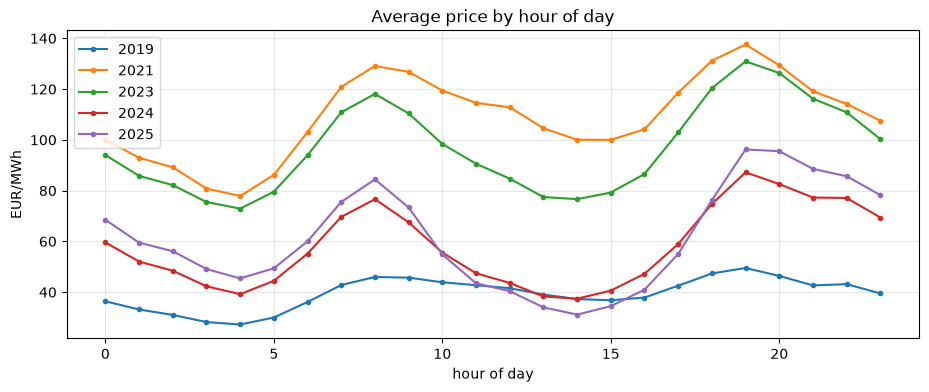

In [3]:
profile = price.groupby([price.index.year, price.index.hour]).mean().unstack(0)
ax = profile[[2019, 2021, 2023, 2024, 2025]].plot(marker=".")
ax.set(xlabel="hour of day", ylabel="EUR/MWh", title="Average price by hour of day")
plt.show()

## Generation mix (monthly mean, realized)

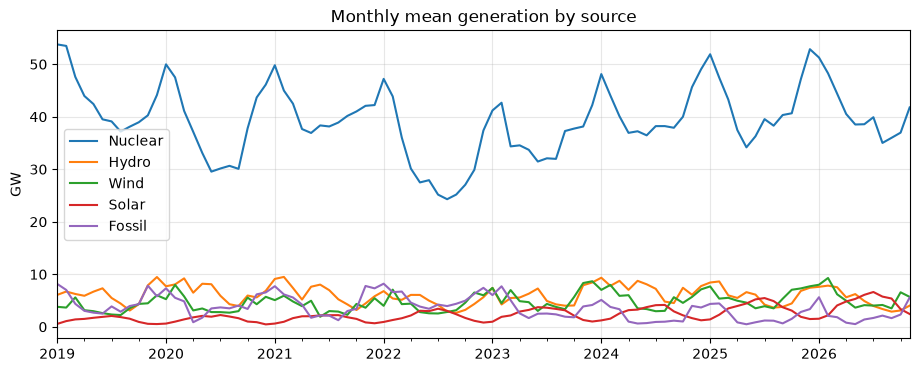

In [4]:
groups = {
    "Nuclear": ["Nuclear"],
    "Hydro": [c for c in generation.columns if c.startswith("Hydro")],
    "Wind": [c for c in generation.columns if c.startswith("Wind")],
    "Solar": ["Solar"],
    "Fossil": [c for c in generation.columns if c.startswith("Fossil")],
}
mix = pd.DataFrame({k: generation[v].sum(axis=1, min_count=1) for k, v in groups.items()})
ax = (mix.resample("MS").mean() / 1000).plot()
ax.set(ylabel="GW", xlabel="", title="Monthly mean generation by source")
plt.show()

## Fundamental drivers

*Residual load* (load forecast minus wind and solar forecasts) is the demand left for dispatchable plants; it is the main fundamental driver of price. Demand itself is strongly temperature-sensitive in France because of widespread electric heating.

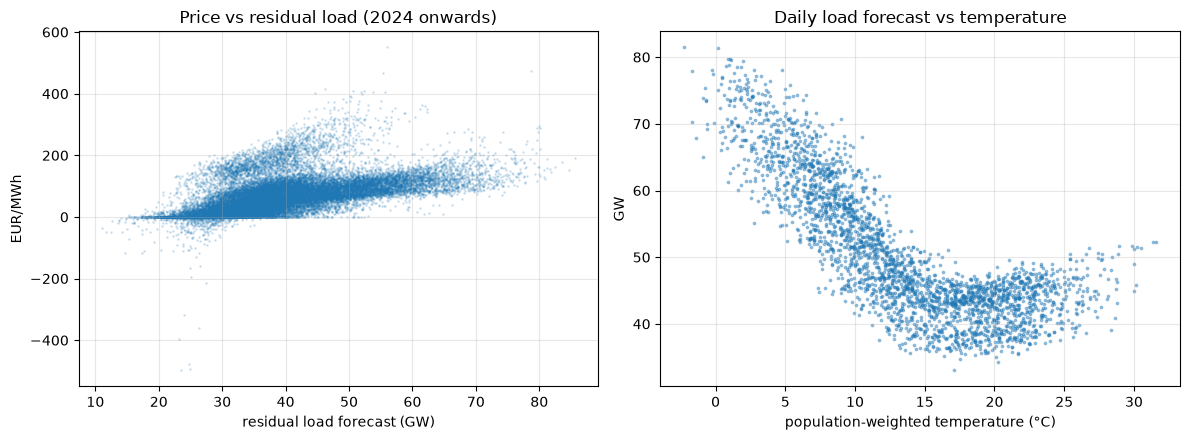

In [5]:
residual = load - wind_solar
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
recent = price.index >= "2024-01-01"
axes[0].scatter(residual[recent] / 1000, price[recent], s=1, alpha=0.15)
axes[0].set(xlabel="residual load forecast (GW)", ylabel="EUR/MWh",
            title="Price vs residual load (2024 onwards)")
daily = pd.DataFrame({"load": load, "temp": weather["temperature_c"]}).resample("D").mean()
axes[1].scatter(daily["temp"], daily["load"] / 1000, s=3, alpha=0.4)
axes[1].set(xlabel="population-weighted temperature (°C)", ylabel="GW",
            title="Daily load forecast vs temperature")
plt.tight_layout()
plt.show()